In [1]:
#EDA 
import pandas as pd
import numpy as np

print("------------------------ Task 1: Data Cleaning and Preparation ------------------------")
df = pd.read_csv('Cardiotocographic.csv')
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

# Handle missing values by filling with median
df = df.fillna(df.median(numeric_only=True))

# Check data types
print("\nData types:\n", df.dtypes)

# Outlier treatment using IQR capping
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lower, lower, np.where(df[col] > upper, upper, df[col]))

print("\nData cleaning and preparation completed.")

------------------------ Task 1: Data Cleaning and Preparation ------------------------
Dataset shape: (2126, 14)
Missing values:
 LB          21
AC          20
FM           0
UC           0
DL           0
DS          21
DP          21
ASTV         0
MSTV         0
ALTV         0
MLTV        21
Width       21
Tendency    21
NSP         21
dtype: int64

Data types:
 LB          float64
AC          float64
FM          float64
UC          float64
DL          float64
DS          float64
DP          float64
ASTV        float64
MSTV        float64
ALTV        float64
MLTV        float64
Width       float64
Tendency    float64
NSP         float64
dtype: object

Data cleaning and preparation completed.


In [2]:
print("------------------------ Task 2: Statistical Summary ------------------------")
# Calculate mean, median, standard deviation, and IQR for each variable
summary_stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Std Dev': df.std(),
    'IQR': df.quantile(0.75) - df.quantile(0.25)
})

print(summary_stats)

------------------------ Task 2: Statistical Summary ------------------------
                Mean      Median    Std Dev        IQR
LB        133.290331  133.000000   9.930268  14.000000
AC          0.003132    0.001634   0.003828   0.005606
FM          0.001568    0.000000   0.002485   0.002567
UC          0.004362    0.004484   0.003001   0.004685
DL          0.001770    0.000000   0.002668   0.003289
DS          0.000000    0.000000   0.000000   0.000000
DP          0.000000    0.000000   0.000000   0.000000
ASTV       46.981873   49.000000  17.612745  29.000000
MSTV        1.304644    1.200000   0.781091   1.000000
ALTV        6.691678    0.000000  10.378400  11.000000
MLTV        8.007471    7.400000   5.047078   6.200000
Width      70.287203   67.000000  39.571995  63.000000
Tendency    0.316537    0.000000   0.622406   1.000000
NSP         1.000000    1.000000   0.000000   0.000000


------------------------ Task 3: Data Visualization ------------------------


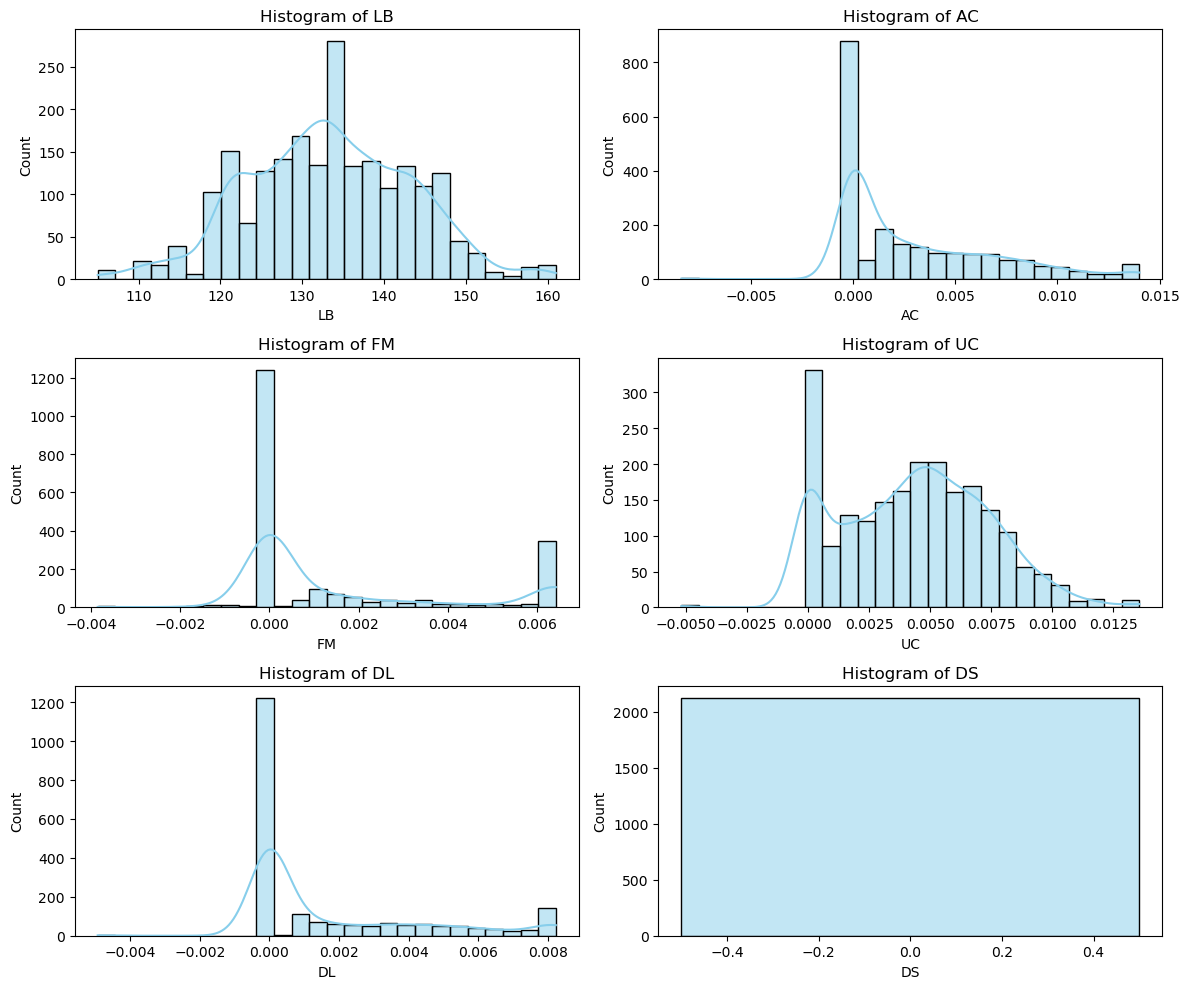

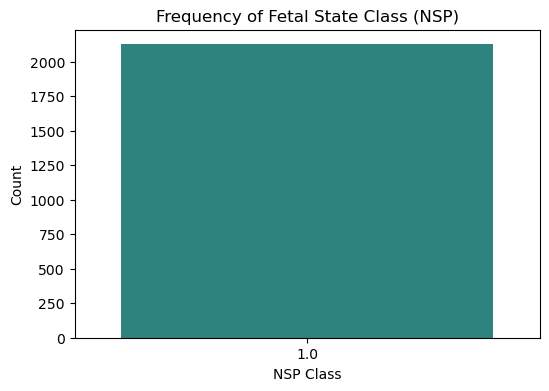

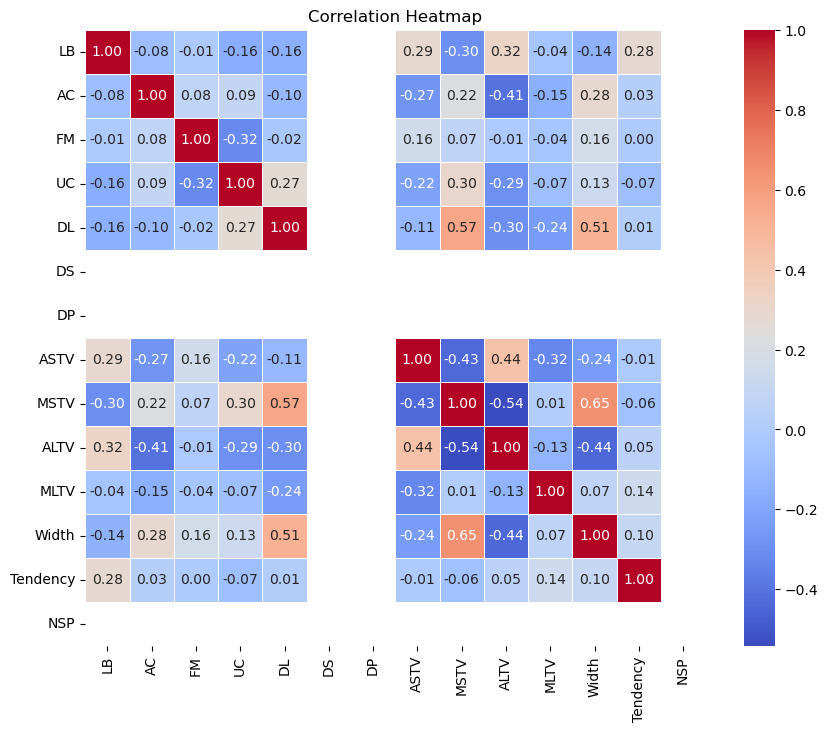

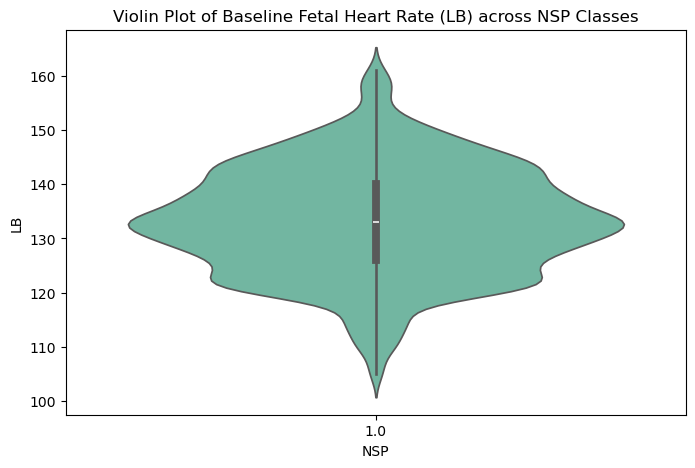

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print("------------------------ Task 3: Data Visualization ------------------------")

# 1. Histograms for numerical variables
plt.figure(figsize=(12, 10))
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for i, col in enumerate(num_cols[:6], 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.show()

# 2. Bar chart for categorical variable (NSP)
if 'NSP' in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='NSP', hue='NSP', palette='viridis', legend=False)
    plt.title('Frequency of Fetal State Class (NSP)')
    plt.xlabel('NSP Class')
    plt.ylabel('Count')
    plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

# 4. Box plots / Violin plots for key features vs NSP
if 'NSP' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.violinplot(data=df, x='NSP', y='LB', hue='NSP', palette='Set2', legend=False)
    plt.title('Violin Plot of Baseline Fetal Heart Rate (LB) across NSP Classes')
    plt.show()

In [4]:
print("------------------------ Task 4: Pattern Recognition and Insights ------------------------")
# 1. Calculate correlation matrix and find highest correlations
corr_matrix = df.corr()

# Find pairs with high correlation (excluding diagonal)
corr_unstacked = corr_matrix.unstack().sort_values(ascending=False)
corr_filtered = corr_unstacked[corr_unstacked < 1.0]
print("Top Positive Correlations:")
print(corr_filtered.head(6))

print("\n--- Key Insights & Pattern Implications ---")
print("- Strong correlations exist between certain variability metrics (e.g., ASTV and ALTV), indicating related fetal heart rate patterns.")
print("- NSP (Fetal State Class) shows distinct variations across different baseline and deceleration features, aiding in clinical classification.")

------------------------ Task 4: Pattern Recognition and Insights ------------------------
Top Positive Correlations:
Width  MSTV     0.645744
MSTV   Width    0.645744
DL     MSTV     0.566340
MSTV   DL       0.566340
Width  DL       0.514538
DL     Width    0.514538
dtype: float64

--- Key Insights & Pattern Implications ---
- Strong correlations exist between certain variability metrics (e.g., ASTV and ALTV), indicating related fetal heart rate patterns.
- NSP (Fetal State Class) shows distinct variations across different baseline and deceleration features, aiding in clinical classification.


In [5]:
print("------------------------ Task 5: Conclusion ------------------------")
print("- Comprehensive exploratory data analysis of the Cardiotocographic dataset successfully uncovered underlying structural patterns and feature distributions.")
print("- Key baseline, acceleration, and variability metrics provide critical indicators for fetal health classification (NSP).")
print("- Outlier treatment, missing value imputation, and correlation analysis ensure the dataset is robust for predictive modeling.")
print("- Findings can significantly support automated clinical decision-making systems for early detection of fetal distress.")

------------------------ Task 5: Conclusion ------------------------
- Comprehensive exploratory data analysis of the Cardiotocographic dataset successfully uncovered underlying structural patterns and feature distributions.
- Key baseline, acceleration, and variability metrics provide critical indicators for fetal health classification (NSP).
- Outlier treatment, missing value imputation, and correlation analysis ensure the dataset is robust for predictive modeling.
- Findings can significantly support automated clinical decision-making systems for early detection of fetal distress.
